# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

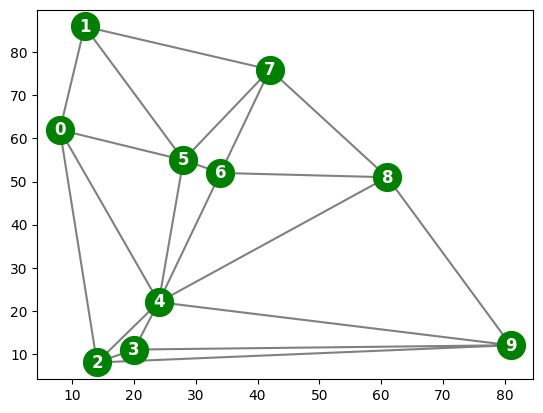

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [12]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [13]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Phần bổ sung (Bài 1 – Bài 4)
Các cell ở dưới nhóm thêm vào notebook gốc (các cell gốc được giữ nguyên). `csp` ở trên là bài toán 4 màu; bên dưới dựng thêm `csp4` (4 màu) và `csp3` (3 màu) để so sánh.

In [14]:
import platform, time
import pandas as pd
import scipy, matplotlib

print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

COLORS4 = ['red', 'blue', 'green', 'orange']   # miền 4 màu
COLORS3 = COLORS4[:3]                          # miền 3 màu


def plot_graph(points, tri, assignment=None, ax=None, title=None):
    # Vẽ đồ thị; nếu có assignment thì tô màu theo TÊN BIẾN (assignment['3'] là màu của đỉnh 3).
    if ax is None:
        ax = plt.gca()
    ax.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray")
    for i in range(len(points)):
        col = 'green' if assignment is None else assignment.get(str(i), 'lightgray')
        ax.plot(points[i, 0], points[i, 1], 'o', color=col, markersize=20)
        ax.annotate(str(i), points[i, :], color='white', fontsize="large", weight='heavy',
                    horizontalalignment='center', verticalalignment='center')
    ax.set_aspect('equal')
    if title:
        ax.set_title(title)

Python 3.13.5 | numpy 2.3.4 | scipy 1.16.3 | matplotlib 3.10.7 | pandas 2.3.3


### Mô hình CSP ⟨X, D, C⟩
* **X** – tập biến: mỗi đỉnh của đồ thị là một biến, `X = {0, 1, …, n−1}` (trong code là các chuỗi `'0'…'9'`).
* **D** – miền giá trị: `Dᵢ = {red, blue, green, orange}` (4 màu) hoặc `Dᵢ = {red, blue, green}` (3 màu), giống nhau cho mọi đỉnh.
* **C** – ràng buộc: với mỗi cạnh `(i, j)` của đồ thị, `color(i) ≠ color(j)` (ràng buộc nhị phân "khác nhau").

**Vì sao chỉ tạo ràng buộc cho cạnh `i < j`?** Danh sách `neighbors` là đối xứng: nếu `j ∈ neighbors[i]` thì cũng có `i ∈ neighbors[j]`, nên mỗi cạnh vô hướng xuất hiện **hai lần**. Ràng buộc `≠` cũng đối xứng (`a ≠ b` ⇔ `b ≠ a`), nên chỉ cần giữ một bản cho mỗi cạnh. Điều kiện `i < j` loại bỏ bản trùng, giúp `constraints` có đúng một phần tử cho mỗi cạnh và giảm một nửa số phép so sánh khi kiểm tra tính nhất quán. Cell dưới đây minh họa.

In [15]:
def build_csp(neighbors, domain):
    # Dựng CSP theo đúng định dạng của notebook gốc: dict gồm variables, domains, constraints
    variables = [str(v) for v in range(len(neighbors))]
    domains = {v: list(domain) for v in variables}

    # ràng buộc nhị phân "không được trùng màu": chỉ giữ cạnh i < j
    constraints = {}
    for i in range(len(neighbors)):
        for j in neighbors[i]:
            if i < j:
                constraints[tuple([str(i), str(j)])] = True
    constraints = constraints.keys()

    return {'variables': variables, 'domains': domains, 'constraints': constraints}


csp4 = build_csp(neighbors, COLORS4)    # 4 màu
csp3 = build_csp(neighbors, COLORS3)    # 3 màu

both_directions = [(str(i), str(j)) for i in range(n) for j in neighbors[i]]
print("Số ràng buộc nếu KHÔNG lọc i<j :", len(both_directions), "(mỗi cạnh bị lặp 2 lần, ví dụ", both_directions[:2], ")")
print("Số ràng buộc khi lọc i<j       :", len(csp4['constraints']))
print()
print("X =", csp4['variables'])
print("D (4 màu) =", csp4['domains']['0'])
print("D (3 màu) =", csp3['domains']['0'])
print("C =", list(csp4['constraints']))

Số ràng buộc nếu KHÔNG lọc i<j : 42 (mỗi cạnh bị lặp 2 lần, ví dụ [('0', '1'), ('0', '2')] )
Số ràng buộc khi lọc i<j       : 21

X = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
D (4 màu) = ['red', 'blue', 'green', 'orange']
D (3 màu) = ['red', 'blue', 'green']
C = [('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')]


### Phép gán đầy đủ và phép gán hợp lệ
* **Phép gán đầy đủ (complete)**: *mọi* biến đã được gán giá trị trong miền của nó.
* **Phép gán hợp lệ / nhất quán (consistent)**: *không có ràng buộc nào bị vi phạm* trong số các biến đã gán (có thể mới chỉ gán một phần).
* **Nghiệm của CSP** = phép gán **vừa đầy đủ vừa hợp lệ**. Đầy đủ chưa chắc là hợp lệ (ví dụ tô cả 10 đỉnh cùng màu đỏ), và hợp lệ chưa chắc là đầy đủ (ví dụ chỉ tô đỏ đỉnh 0).

Khảo sát miền 4 màu và 3 màu: kích thước miền quyết định *có tồn tại nghiệm hay không*. Đồ thị phẳng luôn tô được bằng 4 màu (định lý bốn màu), nhưng với 3 màu thì tùy đồ thị, và các đồ thị Delaunay ngẫu nhiên có rất ít khả năng tô được bằng 3 màu (kết quả thực nghiệm ở Bài 3–4). Cell dưới đây cho thấy một phép gán đầy đủ nhưng vi phạm ràng buộc:

In [16]:
all_red = {v: 'red' for v in csp4['variables']}          # đầy đủ: cả 10 đỉnh đều có màu
violated = [c for c in csp4['constraints'] if all_red[c[0]] == all_red[c[1]]]
print(f"Phép gán 'tất cả đều đỏ': đầy đủ (10/10 đỉnh), nhưng vi phạm {len(violated)}/{len(csp4['constraints'])} ràng buộc -> KHÔNG phải nghiệm.")

Phép gán 'tất cả đều đỏ': đầy đủ (10/10 đỉnh), nhưng vi phạm 21/21 ràng buộc -> KHÔNG phải nghiệm.


## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [17]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [18]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


### Bài 2: Các ca kiểm thử (≥ 3) kèm kết quả mong đợi
Các ca dùng cạnh `(a, b)` đầu tiên của đồ thị và một cặp đỉnh `(u, v)` **không kề nhau**, nên được dựng tự động và đúng với mọi đồ thị.

In [19]:
edge_set = set(csp4['constraints'])
a, b = next(iter(csp4['constraints']))                                   # một cạnh
u, v = next((x, y) for x in csp4['variables'] for y in csp4['variables']
            if x < y and (x, y) not in edge_set and (y, x) not in edge_set)  # một cặp KHÔNG kề

# phép gán đầy đủ và hợp lệ: tô tham lam theo thứ tự đỉnh (chọn màu đầu tiên chưa dùng bởi láng giềng đã tô)
proper = {}
for var in csp4['variables']:
    used = {proper[w] for w in proper if (w, var) in edge_set or (var, w) in edge_set}
    proper[var] = next(c for c in COLORS4 if c not in used)

tests = [
    # (tên ca, assignment, complete mong đợi, consistent mong đợi)
    ("1. Phép gán rỗng",                         {},                          False, True),
    ("2. Một phần, hai đỉnh KỀ khác màu",        {a: 'red', b: 'blue'},       False, True),
    ("3. Một phần, hai đỉnh KỀ cùng màu",        {a: 'red', b: 'red'},        False, False),
    ("4. Một phần, hai đỉnh KHÔNG kề cùng màu",  {u: 'red', v: 'red'},        False, True),
    ("5. Đầy đủ và tô đúng (tô tham lam)",       proper,                      True,  True),
    ("6. Đầy đủ nhưng tất cả cùng màu đỏ",       all_red,                     True,  False),
    ("7. Gán màu NGOÀI miền ('purple')",         {a: 'purple'},               False, True),
]

rows = []
for name, asg, exp_c, exp_k in tests:
    got_c, got_k = complete(asg, csp4), consistent(asg, csp4)
    rows.append({'Ca kiểm thử': name,
                 'complete mong đợi': exp_c, 'complete thực tế': got_c,
                 'consistent mong đợi': exp_k, 'consistent thực tế': got_k,
                 'Đạt': (got_c == exp_c) and (got_k == exp_k)})
test_table = pd.DataFrame(rows)
display(test_table)
assert test_table['Đạt'].all(), "có ca kiểm thử không đạt"
print("Tất cả", len(tests), "ca kiểm thử đạt.")

,Ca kiểm thử,complete mong đợi,complete thực tế,consistent mong đợi,consistent thực tế,Đạt
0,1. Phép gán rỗng,False,False,True,True,True
1,"2. Một phần, hai đỉnh KỀ khác màu",False,False,True,True,True
2,"3. Một phần, hai đỉnh KỀ cùng màu",False,False,False,False,True
3,"4. Một phần, hai đỉnh KHÔNG kề cùng màu",False,False,True,True,True
4,5. Đầy đủ và tô đúng (tô tham lam),True,True,True,True,True
5,6. Đầy đủ nhưng tất cả cùng màu đỏ,True,True,False,False,True
6,7. Gán màu NGOÀI miền ('purple'),False,False,True,True,True


Tất cả 7 ca kiểm thử đạt.


### Nhận xét và cấu trúc `csp`
* `complete()` chỉ kiểm tra **mọi biến đã được gán** (không nhìn ràng buộc); `consistent()` chỉ kiểm tra **không có ràng buộc nào bị vi phạm giữa các biến đã gán** (không quan tâm còn biến chưa gán). Hai điều kiện độc lập: ca 6 là đầy đủ nhưng không nhất quán, ca 2 là nhất quán nhưng chưa đầy đủ. Chỉ khi cả hai cùng đúng (ca 5) mới là **nghiệm**.
* Ca 4 cho thấy "cùng màu" chưa phải lỗi: chỉ lỗi khi hai đỉnh **kề nhau**. Ca 7 cho thấy `consistent()` **không kiểm tra giá trị có thuộc miền hay không**; việc đó do thuật toán tìm kiếm đảm bảo vì nó chỉ thử giá trị lấy từ `domains`.
* **Phép gán từng phần** là điểm trung gian trong cây tìm kiếm (một nút); **nghiệm CSP** là phép gán đầy đủ và nhất quán.

In [20]:
print("csp là dict với các khóa:", list(csp4.keys()))
print("- variables  :", type(csp4['variables']).__name__, "gồm", len(csp4['variables']), "tên biến (chuỗi), ví dụ", csp4['variables'][:3])
print("- domains    :", type(csp4['domains']).__name__, "ánh xạ tên biến -> danh sách giá trị, ví dụ domains['0'] =", csp4['domains']['0'])
print("- constraints:", type(csp4['constraints']).__name__, "gồm", len(csp4['constraints']),
      "bộ (biến1, biến2) với ý nghĩa 'hai biến này phải khác giá trị', ví dụ", list(csp4['constraints'])[:3])

csp là dict với các khóa: ['variables', 'domains', 'constraints']
- variables  : list gồm 10 tên biến (chuỗi), ví dụ ['0', '1', '2']
- domains    : dict ánh xạ tên biến -> danh sách giá trị, ví dụ domains['0'] = ['red', 'blue', 'green', 'orange']
- constraints: dict_keys gồm 21 bộ (biến1, biến2) với ý nghĩa 'hai biến này phải khác giá trị', ví dụ [('0', '1'), ('0', '2'), ('0', '4')]


## Implement Simple Backtracking Search

In [21]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [22]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [23]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
CPU times: user 1.94 ms, sys: 0 ns, total: 1.94 ms
Wall time: 2.12 ms


{'0': 'red',
 '1': 'blue',
 '2': 'blue',
 '3': 'red',
 '4': 'green',
 '5': 'orange',
 '6': 'red',
 '7': 'green',
 '8': 'blue',
 '9': 'orange'}

Plot the resulting coloring

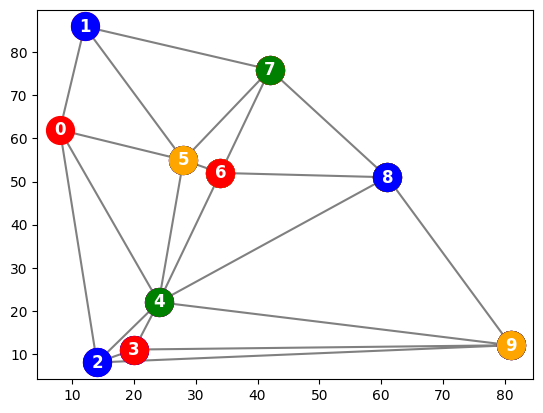

In [24]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

## Bài 3. Backtracking Search và thứ tự chọn biến (phần bổ sung)
Phần dưới lưu lại COUNT của bản gốc, vẽ lại kết quả theo tên biến, rồi cài **MRV**, **LCV** và so sánh trên cùng đồ thị.

In [25]:
count_bt4 = COUNT          # COUNT của bản gốc (lần chạy backtrack_search(csp) ở trên)
print("COUNT của Backtracking gốc =", count_bt4)

COUNT của Backtracking gốc = 11


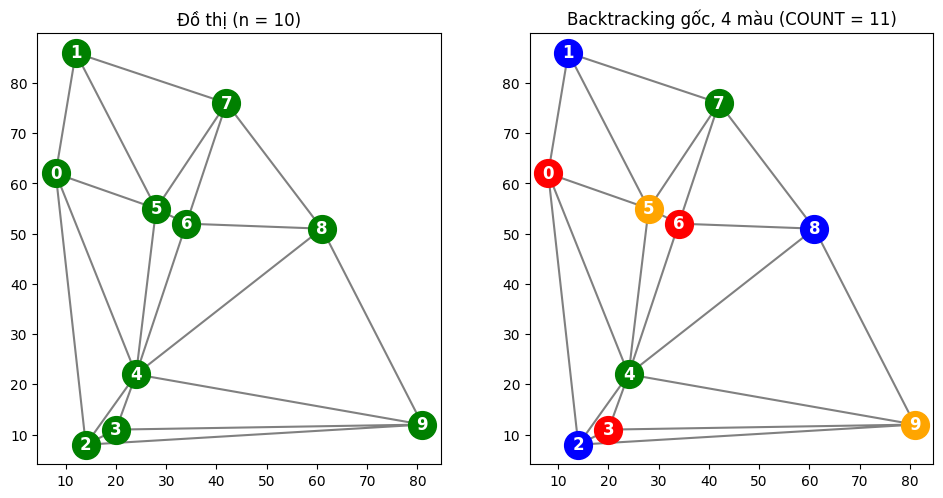

In [26]:
# Trực quan hóa. Lưu ý: vẽ theo TÊN BIẾN (res[str(i)]) thay vì list(res.values())[i] của notebook gốc,
# vì thứ tự chèn của dict KHÔNG trùng thứ tự đỉnh khi dùng MRV.
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_graph(points, tri, ax=axes[0], title="Đồ thị (n = 10)")
plot_graph(points, tri, res, ax=axes[1], title=f"Backtracking gốc, 4 màu (COUNT = {count_bt4})")
plt.tight_layout()
fig.savefig("fig_coloring_n10_4colors.png", dpi=120)
plt.show()

**Cài đặt Minimum Remaining Values (MRV) trên miền còn hợp lệ. Thử bổ sung một chiến lược thứ tự giá trị (ví dụ Least Constraining Value – LCV)**


In [27]:
def build_adj(csp):
    # danh sách kề (đã sắp theo chỉ số đỉnh để kết quả không phụ thuộc vào thứ tự băm)
    adj = {v: [] for v in csp['variables']}
    for x, y in csp['constraints']:
        adj[x].append(y)
        adj[y].append(x)
    return {v: sorted(lst, key=int) for v, lst in adj.items()}


def legal_values(var, assignment, csp, adj):
    # các màu của var KHÔNG trùng màu láng giềng đã gán (miền còn hợp lệ)
    return [c for c in csp['domains'][var] if all(assignment.get(w) != c for w in adj[var])]


def select_unassigned_var_mrv(assignment, csp, adj):
    # MRV: biến chưa gán có ít giá trị hợp lệ nhất; hòa thì lấy biến đứng trước
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    return min(unassigned, key=lambda v: len(legal_values(v, assignment, csp, adj)))


def order_domain_lcv(var, assignment, csp, adj):
    # LCV: màu làm mất ít lựa chọn nhất của láng giềng chưa gán được thử trước
    def rule_out(c):
        return sum(1 for w in adj[var] if w not in assignment and c in legal_values(w, assignment, csp, adj))
    return sorted(legal_values(var, assignment, csp, adj), key=rule_out)   # sorted ổn định: hòa giữ thứ tự miền


class NodeLimit(Exception):
    pass


def backtrack_search_v2(csp, mrv=False, lcv=False, node_limit=None):
    # Backtracking có tùy chọn MRV / LCV. Trả về (assignment hoặc None, trạng thái, COUNT)
    # trạng thái: 'solved' | 'unsat' (đã duyệt hết cây, chứng minh vô nghiệm) | 'limit' (dừng vì hết giới hạn nút)
    adj = build_adj(csp)
    assignment = {}
    count = [0]

    def bt():
        count[0] += 1
        if node_limit is not None and count[0] > node_limit:
            raise NodeLimit
        if len(assignment) == len(csp['variables']):
            return True
        var = select_unassigned_var_mrv(assignment, csp, adj) if mrv else \
            next(v for v in csp['variables'] if v not in assignment)
        values = order_domain_lcv(var, assignment, csp, adj) if lcv else legal_values(var, assignment, csp, adj)
        for val in values:                      # các giá trị này đều nhất quán với láng giềng đã gán
            assignment[var] = val
            if bt():
                return True
            del assignment[var]
        return False

    try:
        found = bt()
        status = 'solved' if found else 'unsat'
    except NodeLimit:
        found, status = False, 'limit'
    return (dict(assignment) if found else None), status, count[0]

**So sánh kết quả với phiên bản gốc trên cùng đồ thị (n=10, seed 1111)**
Trước hết kiểm tra bản `backtrack_search_v2` (không MRV, không LCV) khớp với bản gốc, rồi so sánh 4 cấu hình với 4 màu và 3 màu.

In [28]:
def compare_on(csp, label):
    global COUNT
    rows = []
    for name, kw in [("Backtracking gốc (biến đầu tiên)", None),
                     ("+ MRV", dict(mrv=True)),
                     ("+ LCV", dict(lcv=True)),
                     ("+ MRV + LCV", dict(mrv=True, lcv=True))]:
        t0 = time.perf_counter()
        if kw is None:
            COUNT = 0
            sol = backtrack({}, csp)
            cnt, status = COUNT, ('solved' if sol is not None else 'unsat')
        else:
            sol, status, cnt = backtrack_search_v2(csp, **kw)
        dt = time.perf_counter() - t0
        ok = (sol is not None) and complete(sol, csp) and consistent(sol, csp)
        rows.append({'Miền': label, 'Thuật toán': name, 'Kết quả': status, 'COUNT': cnt,
                     'Thời gian (ms)': round(dt * 1000, 3), 'Nghiệm hợp lệ': ok if sol is not None else '-'})
    return pd.DataFrame(rows)


# kiểm tra bản v2 thuần khớp bản gốc
_, _, c_v2 = backtrack_search_v2(csp4)
assert c_v2 == count_bt4, (c_v2, count_bt4)
print("backtrack_search_v2 (không MRV/LCV) cho COUNT =", c_v2, "= COUNT bản gốc  ✓")

cmp_table = pd.concat([compare_on(csp4, "4 màu"), compare_on(csp3, "3 màu")], ignore_index=True)
display(cmp_table)

backtrack_search_v2 (không MRV/LCV) cho COUNT = 11 = COUNT bản gốc  ✓


,Miền,Thuật toán,Kết quả,COUNT,Thời gian (ms),Nghiệm hợp lệ
0,4 màu,Backtracking gốc (biến đầu tiên),solved,11,0.350,True
1,4 màu,+ MRV,solved,11,0.548,True
2,4 màu,+ LCV,solved,11,0.418,True
3,4 màu,+ MRV + LCV,solved,11,0.663,True
4,3 màu,Backtracking gốc (biến đầu tiên),unsat,70,3.234,-
5,3 màu,+ MRV,unsat,34,1.125,-
6,3 màu,+ LCV,unsat,70,1.918,-
7,3 màu,+ MRV + LCV,unsat,34,2.703,-


**Nhận xét (đồ thị mẫu, seed 1111):**
* **4 màu**: cả bốn cấu hình đều có `COUNT = 11 = n + 1` (1 nút gốc + 10 lần gán), tức là *không quay lui lần nào*. Đồ thị mẫu quá dễ (4 màu là dư và các đỉnh được đánh số từ trái sang phải) nên MRV hay LCV không còn gì để cải thiện; chúng còn chậm hơn một chút vì mỗi nút phải tính thêm miền hợp lệ của các biến chưa gán.
* **3 màu**: đồ thị này **vô nghiệm**, nên thuật toán phải duyệt hết cây tìm kiếm mới kết luận được. Bản gốc duyệt **70 nút**; **MRV chỉ cần 34 nút** (giảm khoảng một nửa) vì chọn biến "chật" nhất trước nên các nhánh cụt bị cắt gần gốc. **LCV giữ nguyên 70 nút** (và MRV + LCV vẫn 34): khi không có nghiệm thì mọi nhánh đều phải bị duyệt hết, nên thứ tự thử giá trị không thay đổi tổng số nút. LCV chỉ có thể giúp khi *có nghiệm* để tìm sớm hơn.
* Phép gán do MRV trả về có thứ tự chèn vào `dict` khác thứ tự đỉnh (ô trên), vì vậy phải vẽ theo tên biến chứ không theo `list(res.values())[i]` như notebook gốc.

Để thấy khác biệt rõ giữa các chiến lược, cần đồ thị lớn hơn và nhiều đồ thị: xem thí nghiệm ở Bài 4.3.

In [29]:
res_mrv, _, cnt_mrv = backtrack_search_v2(csp4, mrv=True)
print("MRV + Backtracking (4 màu): COUNT =", cnt_mrv, "| hợp lệ:", complete(res_mrv, csp4) and consistent(res_mrv, csp4))
print("Kết quả:", dict(sorted(res_mrv.items(), key=lambda kv: int(kv[0]))))
print("Phép gán MRV vẽ theo thứ tự chèn của dict:", list(res_mrv.keys()), "(không phải 0,1,2,...)")

MRV + Backtracking (4 màu): COUNT = 11 | hợp lệ: True
Kết quả: {'0': 'red', '1': 'blue', '2': 'green', '3': 'red', '4': 'blue', '5': 'green', '6': 'red', '7': 'orange', '8': 'green', '9': 'orange'}
Phép gán MRV vẽ theo thứ tự chèn của dict: ['0', '1', '5', '4', '2', '3', '9', '6', '7', '8'] (không phải 0,1,2,...)


## Bài 4. Forward Checking và Min-Conflicts

### Forward Checking (có hoàn tác miền khi quay lui)
Sau khi gán màu `c` cho đỉnh `x`, Forward Checking **xóa `c` khỏi miền của mọi láng giềng chưa gán** của `x`. Nếu miền của một láng giềng trở thành rỗng thì nhánh hiện tại chắc chắn thất bại và quay lui ngay, không cần đi sâu thêm. Mọi giá trị đã xóa được ghi vào một danh sách (`removed`) để **hoàn tác** khi quay lui và thử màu khác.

In [30]:
def backtrack_search_fc(csp, mrv=False, lcv=False, node_limit=None):
    # Backtracking + Forward Checking. Trả về (assignment hoặc None, trạng thái, COUNT, số giá trị bị loại)
    adj = build_adj(csp)
    dom = {v: set(csp['domains'][v]) for v in csp['variables']}      # miền còn lại (thay đổi trong lúc tìm kiếm)
    assignment = {}
    stats = {'count': 0, 'pruned': 0}

    def cur_values(v):
        return [c for c in csp['domains'][v] if c in dom[v]]          # giữ thứ tự miền gốc

    def bt():
        stats['count'] += 1
        if node_limit is not None and stats['count'] > node_limit:
            raise NodeLimit
        if len(assignment) == len(csp['variables']):
            return True

        unassigned = [v for v in csp['variables'] if v not in assignment]
        var = min(unassigned, key=lambda v: len(dom[v])) if mrv else unassigned[0]

        values = cur_values(var)
        if lcv:   # màu xuất hiện trong miền ít láng giềng chưa gán nhất được thử trước
            values = sorted(values, key=lambda c: sum(1 for w in adj[var] if w not in assignment and c in dom[w]))

        for val in values:
            assignment[var] = val
            removed = []                                              # nhật ký để hoàn tác
            wipeout = False
            for w in adj[var]:
                if w not in assignment and val in dom[w]:
                    dom[w].remove(val)
                    removed.append(w)
                    stats['pruned'] += 1
                    if not dom[w]:                                    # miền rỗng -> thất bại sớm
                        wipeout = True
                        break
            if not wipeout and bt():
                return True
            for w in removed:                                         # HOÀN TÁC miền khi quay lui
                dom[w].add(val)
            del assignment[var]
        return False

    try:
        found = bt()
        status = 'solved' if found else 'unsat'
    except NodeLimit:
        found, status = False, 'limit'
    return (dict(assignment) if found else None), status, stats['count'], stats['pruned']


rows = []
for label, csp in (("4 màu", csp4), ("3 màu", csp3)):
    for name, use_fc, kw in (("Backtracking gốc", False, dict()), ("MRV (không FC)", False, dict(mrv=True)),
                             ("Forward Checking", True, dict()), ("Forward Checking + MRV", True, dict(mrv=True))):
        t0 = time.perf_counter()
        if not use_fc:
            sol, status, cnt = backtrack_search_v2(csp, **kw)
            pruned = 0
        else:
            sol, status, cnt, pruned = backtrack_search_fc(csp, **kw)
        dt = time.perf_counter() - t0
        if sol is not None:
            assert complete(sol, csp) and consistent(sol, csp)
        rows.append({'Miền': label, 'Thuật toán': name, 'Kết quả': status, 'COUNT': cnt,
                     'Số lần loại giá trị': pruned, 'Thời gian (ms)': round(dt * 1000, 3)})
fc_table = pd.DataFrame(rows)
display(fc_table)

,Miền,Thuật toán,Kết quả,COUNT,Số lần loại giá trị,Thời gian (ms)
0,4 màu,Backtracking gốc,solved,11,0,0.122
1,4 màu,MRV (không FC),solved,11,0,0.350
2,4 màu,Forward Checking,solved,11,18,0.112
3,4 màu,Forward Checking + MRV,solved,11,20,0.099
4,3 màu,Backtracking gốc,unsat,70,0,0.332
5,3 màu,MRV (không FC),unsat,34,0,1.043
6,3 màu,Forward Checking,unsat,34,108,0.143
7,3 màu,Forward Checking + MRV,unsat,28,90,0.119


**Nhận xét (đồ thị mẫu):**
* **4 màu**: mọi cấu hình đều `COUNT = 11` (không quay lui); Forward Checking chỉ tốn thêm công việc loại giá trị (18 lần loại màu khỏi miền láng giềng) mà không giảm được số nút.
* **3 màu (vô nghiệm)**: số nút giảm dần theo thứ tự **70** (gốc) → **34** (chỉ MRV hoặc chỉ Forward Checking) → **28** (Forward Checking + MRV). Forward Checking bắt được ngõ cụt ngay khi một láng giềng hết màu (miền rỗng), không cần chờ tới lượt chọn đỉnh đó; MRV đưa đỉnh sắp hết màu lên sớm. Hai kỹ thuật bổ sung cho nhau.
* Cột "Số lần loại giá trị" cho thấy chi phí: FC + MRV loại 90 giá trị để tiết kiệm 42 nút so với bản gốc. Số nút (`COUNT`) không phản ánh đủ chi phí mỗi nút, vì vậy cần so cả thời gian (xem Bài 4.3).

### Min-Conflicts (tìm kiếm cục bộ)
Khởi tạo **một phép gán đầy đủ ngẫu nhiên** (có thể vi phạm ràng buộc). Mỗi bước: chọn ngẫu nhiên một đỉnh **đang vi phạm** (cùng màu với ít nhất một láng giềng), rồi đổi nó sang màu **ít vi phạm nhất** (hòa thì chọn ngẫu nhiên). Dừng khi không còn vi phạm (đã tìm được nghiệm) hoặc hết `max_steps` bước; khi đó có thể **khởi động lại** (random restart) tối đa `max_restarts` lần. Các số liệu ghi nhận: số bước, số bước làm giảm vi phạm của đỉnh được chọn ("uphill"), số lần khởi động lại. Min-Conflicts là tìm kiếm cục bộ nên **không chứng minh được vô nghiệm**: thất bại chỉ có nghĩa là chưa tìm thấy.

Min-Conflicts, 4 màu, n = 10: thành công = True, số bước = 5, bước cải thiện = 3, khởi động lại = 0
Nghiệm hợp lệ (complete & consistent): True
Min-Conflicts, 3 màu, n = 10 (đồ thị seed 1111 vô nghiệm): thành công = False, số bước = 12000, khởi động lại = 3


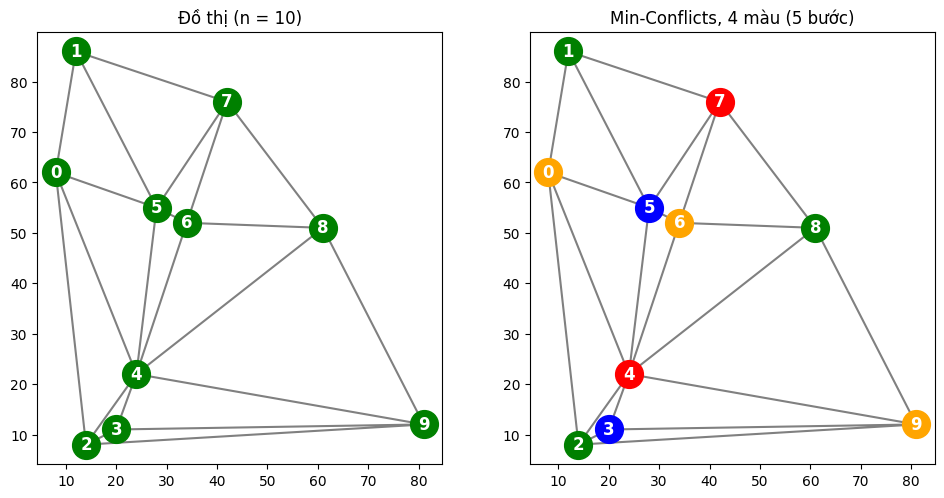

In [31]:
def min_conflicts(csp, adj, rng, max_steps=3000, max_restarts=3):
    # Trả về (assignment hoặc None, thành công?, tổng số bước, số bước cải thiện, số lần khởi động lại đã dùng)
    variables = csp['variables']
    colors = csp['domains'][variables[0]]
    steps = uphill = 0

    for restart in range(max_restarts + 1):
        a = {v: colors[rng.integers(len(colors))] for v in variables}          # phép gán đầy đủ ngẫu nhiên
        bad = {v: any(a[w] == a[v] for w in adj[v]) for v in variables}         # đỉnh nào đang vi phạm
        for _ in range(max_steps):
            conflicted = [v for v in variables if bad[v]]
            if not conflicted:
                return a, True, steps, uphill, restart
            v = conflicted[rng.integers(len(conflicted))]                       # chọn ngẫu nhiên một biến vi phạm
            cnt = {c: sum(a[w] == c for w in adj[v]) for c in colors}          # số vi phạm nếu v nhận màu c
            best = min(cnt.values())
            cand = [c for c in colors if cnt[c] == best]
            new = cand[rng.integers(len(cand))]
            if cnt[new] < cnt[a[v]]:
                uphill += 1
            a[v] = new
            steps += 1
            for w in [v] + adj[v]:                                              # chỉ v và láng giềng đổi trạng thái
                bad[w] = any(a[x] == a[w] for x in adj[w])
        if not any(bad.values()):
            return a, True, steps, uphill, restart
    return None, False, steps, uphill, max_restarts


adj4 = build_adj(csp4)
rng = np.random.default_rng(0)
sol_mc, ok_mc, steps_mc, up_mc, rs_mc = min_conflicts(csp4, adj4, rng)
print(f"Min-Conflicts, 4 màu, n = 10: thành công = {ok_mc}, số bước = {steps_mc}, bước cải thiện = {up_mc}, khởi động lại = {rs_mc}")
print("Nghiệm hợp lệ (complete & consistent):", complete(sol_mc, csp4) and consistent(sol_mc, csp4))

adj3 = build_adj(csp3)
sol3, ok3, st3, up3, rs3 = min_conflicts(csp3, adj3, np.random.default_rng(0))
print(f"Min-Conflicts, 3 màu, n = 10 (đồ thị seed 1111 vô nghiệm): thành công = {ok3}, số bước = {st3}, khởi động lại = {rs3}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
plot_graph(points, tri, ax=axes[0], title="Đồ thị (n = 10)")
plot_graph(points, tri, sol_mc, ax=axes[1], title=f"Min-Conflicts, 4 màu ({steps_mc} bước)")
plt.tight_layout()
fig.savefig("fig_min_conflicts_n10_4colors.png", dpi=120)
plt.show()

### Thí nghiệm trên nhiều đồ thị ngẫu nhiên
* Kích thước `n ∈ {10, 20, 30, 50, 75, 100}`; với mỗi `n`, **20 đồ thị** (seed `0..19`); miền 3 màu và 4 màu. Điểm được chọn **không trùng nhau** (khác với `randint` ở phần mẫu, có thể cho điểm trùng và làm hỏng tam giác hóa khi `n` lớn).
* Mọi thuật toán chạy trên **cùng** các đồ thị. Thuật toán chính xác dùng giới hạn `node_limit = 100000` nút; nếu chạm giới hạn thì ghi nhận `limit` (**không** được hiểu là vô nghiệm).
* Min-Conflicts: `max_steps = 3000` mỗi lần, `max_restarts = 3`, `rng` có seed cố định theo đồ thị.
* "Đồ thị có nghiệm" được xác định bằng thuật toán chính xác (FC + MRV), dùng làm mốc để đánh giá Min-Conflicts.

In [32]:
def make_instance(n, seed):
    # n điểm KHÔNG trùng nhau trong lưới 100x100, sắp theo hoành độ, rồi tam giác hóa Delaunay
    rng = np.random.default_rng(seed)
    idx = rng.choice(100 * 100, n, replace=False)
    pts = np.c_[idx // 100, idx % 100]
    pts = pts[np.argsort(pts[:, 0], kind="stable")]
    tr = Delaunay(pts)
    indptr, indices = tr.vertex_neighbor_vertices
    nbs = [np.sort(indices[indptr[k]:indptr[k + 1]]) for k in range(len(indptr) - 1)]
    return pts, tr, nbs


SIZES = [10, 20, 30, 50, 75, 100]
SEEDS = list(range(20))
NODE_LIMIT = 100000

EXACT = [
    ("Backtracking",             lambda csp: backtrack_search_v2(csp, node_limit=NODE_LIMIT)),
    ("MRV + Backtracking",       lambda csp: backtrack_search_v2(csp, mrv=True, node_limit=NODE_LIMIT)),
    ("LCV + Backtracking",       lambda csp: backtrack_search_v2(csp, lcv=True, node_limit=NODE_LIMIT)),
    ("MRV + LCV + Backtracking", lambda csp: backtrack_search_v2(csp, mrv=True, lcv=True, node_limit=NODE_LIMIT)),
    ("Forward Checking",         lambda csp: backtrack_search_fc(csp, node_limit=NODE_LIMIT)[:3]),
    ("Forward Checking + MRV",   lambda csp: backtrack_search_fc(csp, mrv=True, node_limit=NODE_LIMIT)[:3]),
]

raw = []
for n_ in SIZES:
    for k, dom in ((4, COLORS4), (3, COLORS3)):
        for seed in SEEDS:
            _, _, nbs = make_instance(n_, seed)
            csp = build_csp(nbs, dom)
            edges = len(csp['constraints'])

            truth = None                                          # có nghiệm hay không (từ FC + MRV)
            for name, fn in EXACT:
                t0 = time.perf_counter()
                sol, status, cnt = fn(csp)
                dt = time.perf_counter() - t0
                if sol is not None:
                    assert complete(sol, csp) and consistent(sol, csp)
                if name == "Forward Checking + MRV":
                    truth = (status == 'solved')
                raw.append(dict(algorithm=name, n=n_, colors=k, seed=seed, edges=edges, status=status,
                                count=cnt, time=dt, uphill=np.nan, restarts=np.nan, metric='COUNT (nút)'))

            adj = build_adj(csp)
            t0 = time.perf_counter()
            sol, ok, steps, up, rs = min_conflicts(csp, adj, np.random.default_rng(10_000 + seed))
            dt = time.perf_counter() - t0
            if sol is not None:
                assert complete(sol, csp) and consistent(sol, csp)
            raw.append(dict(algorithm="Min-Conflicts", n=n_, colors=k, seed=seed, edges=edges,
                            status='solved' if ok else 'fail', count=steps, time=dt,
                            uphill=up, restarts=rs, metric='số bước'))
            # gắn nhãn "đồ thị có nghiệm" cho mọi dòng vừa thêm
            for r in raw[-(len(EXACT) + 1):]:
                r['satisfiable'] = truth

raw = pd.DataFrame(raw)
print("Tổng số lần chạy:", len(raw), "| số lần chạm node_limit:", int((raw.status == 'limit').sum()))

Tổng số lần chạy: 1680 | số lần chạm node_limit: 0


In [33]:
def aggregate(g):
    solved = g.status == 'solved'
    sat = g.satisfiable.astype(bool)
    return pd.Series({
        'runs': len(g),
        'avg_edges': g.edges.mean(),
        'sat_pct': 100 * sat.mean(),
        'solved_pct': 100 * solved.mean(),
        'solved_pct_of_satisfiable': 100 * solved[sat].mean() if sat.any() else np.nan,
        'proven_unsat_pct': 100 * (g.status == 'unsat').mean(),
        'limit_or_fail_pct': 100 * g.status.isin(['limit', 'fail']).mean(),
        'avg_count_all': g['count'].mean(),
        'avg_count_solved': g.loc[solved, 'count'].mean() if solved.any() else np.nan,
        'avg_uphill': g.uphill.mean(),
        'avg_restarts': g.restarts.mean(),
        'avg_time_s': g.time.mean(),
        'count_metric': g.metric.iloc[0],
    })


records = []
for (alg, n_, k), g in raw.groupby(['algorithm', 'n', 'colors'], sort=False):
    records.append({'algorithm': alg, 'n': n_, 'colors': k, **aggregate(g).to_dict()})
results = pd.DataFrame(records).sort_values(['colors', 'n', 'algorithm']).reset_index(drop=True)
results = results.round({'avg_edges': 2, 'sat_pct': 1, 'solved_pct': 1, 'solved_pct_of_satisfiable': 1,
                         'proven_unsat_pct': 1, 'limit_or_fail_pct': 1, 'avg_count_all': 2, 'avg_count_solved': 2,
                         'avg_uphill': 2, 'avg_restarts': 2, 'avg_time_s': 6})
results.to_csv("results_coloring.csv", index=False, encoding="utf-8")
print("Đã lưu results_coloring.csv:", results.shape[0], "dòng,", results.shape[1], "cột")
display(results.head(8))

Đã lưu results_coloring.csv: 84 dòng, 16 cột


,algorithm,n,colors,runs,avg_edges,sat_pct,solved_pct,solved_pct_of_satisfiable,proven_unsat_pct,limit_or_fail_pct,avg_count_all,avg_count_solved,avg_uphill,avg_restarts,avg_time_s,count_metric
0,Backtracking,10,3,20,21.00,10.0,10.0,100.0,90.0,0.0,44.3,11.0,NaN,NaN,0.000164,COUNT (nút)
1,Forward Checking,10,3,20,21.00,10.0,10.0,100.0,90.0,0.0,27.5,11.0,NaN,NaN,0.000138,COUNT (nút)
2,Forward Checking + MRV,10,3,20,21.00,10.0,10.0,100.0,90.0,0.0,23.6,11.0,NaN,NaN,0.000125,COUNT (nút)
3,LCV + Backtracking,10,3,20,21.00,10.0,10.0,100.0,90.0,0.0,44.3,11.0,NaN,NaN,0.000409,COUNT (nút)
4,MRV + Backtracking,10,3,20,21.00,10.0,10.0,100.0,90.0,0.0,29.0,11.0,NaN,NaN,0.000455,COUNT (nút)
5,MRV + LCV + Backtracking,10,3,20,21.00,10.0,10.0,100.0,90.0,0.0,29.0,11.0,NaN,NaN,0.000667,COUNT (nút)
6,Min-Conflicts,10,3,20,21.00,10.0,10.0,100.0,0.0,90.0,10801.9,19.0,15.4,2.7,0.117450,số bước
7,Backtracking,20,3,20,48.95,0.0,0.0,NaN,100.0,0.0,67.3,NaN,NaN,NaN,0.000222,COUNT (nút)


### Số cạnh (ràng buộc) trung bình theo `n`
Đồ thị phẳng có tối đa `3n − 6` cạnh; tam giác hóa Delaunay gần đạt cận này (đỉnh nằm trên biên bao lồi làm giảm số cạnh).

In [34]:
edge_tbl = (results[results.algorithm == 'Backtracking'].query("colors == 4")[['n', 'avg_edges']]
            .assign(**{'3n - 6': lambda d: 3 * d.n - 6, 'cạnh / đỉnh': lambda d: (d.avg_edges / d.n).round(2)})
            .rename(columns={'avg_edges': 'Số cạnh trung bình (20 đồ thị)'}).reset_index(drop=True))
display(edge_tbl)

,n,Số cạnh trung bình (20 đồ thị),3n - 6,cạnh / đỉnh
0,10,21.00,24,2.10
1,20,48.95,54,2.45
2,30,78.45,84,2.62
3,50,136.55,144,2.73
4,75,210.90,219,2.81
5,100,283.90,294,2.84


### Biểu đồ so sánh COUNT và thời gian

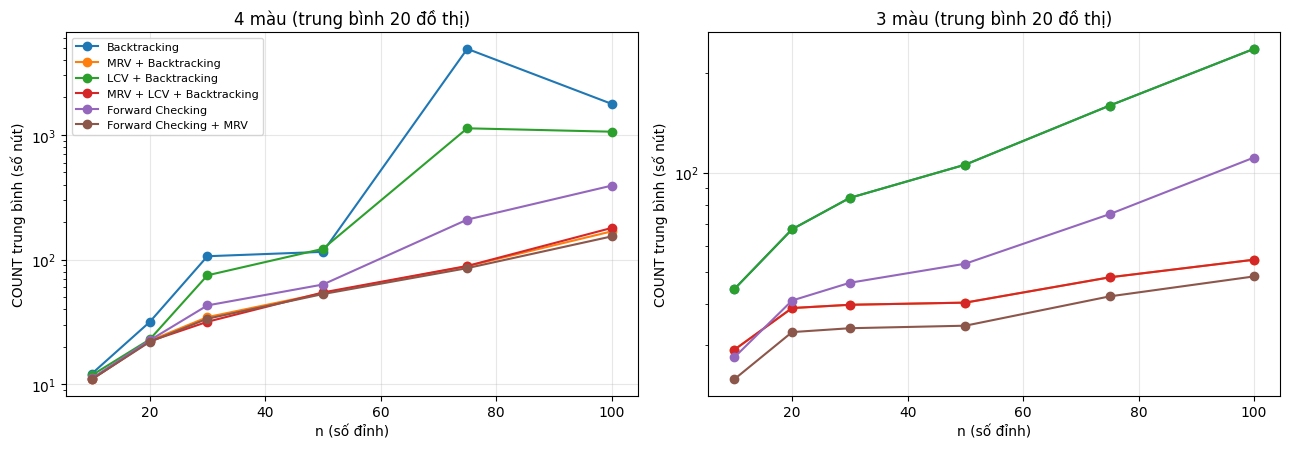

In [35]:
algs_exact = [a for a, _ in EXACT]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for ax, k in zip(axes, (4, 3)):
    for alg in algs_exact:
        d = results[(results.algorithm == alg) & (results.colors == k)]
        ax.plot(d.n, d.avg_count_all, marker='o', label=alg)
    ax.set_xlabel("n (số đỉnh)")
    ax.set_ylabel("COUNT trung bình (số nút)")
    ax.set_yscale('log')
    ax.set_title(f"{k} màu (trung bình 20 đồ thị)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig("fig_count_vs_n.png", dpi=120)
plt.show()

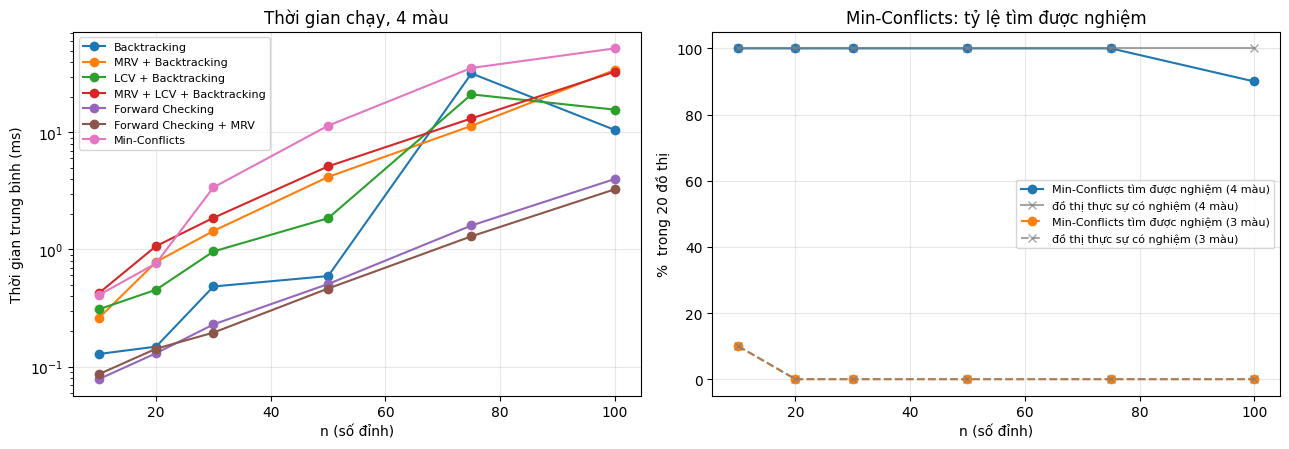

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# (trái) thời gian chạy trung bình, 4 màu, mọi thuật toán kể cả Min-Conflicts
for alg in algs_exact + ["Min-Conflicts"]:
    d = results[(results.algorithm == alg) & (results.colors == 4)]
    axes[0].plot(d.n, d.avg_time_s * 1000, marker='o', label=alg)
axes[0].set_xlabel("n (số đỉnh)")
axes[0].set_ylabel("Thời gian trung bình (ms)")
axes[0].set_yscale('log')
axes[0].set_title("Thời gian chạy, 4 màu")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

# (phải) tỷ lệ Min-Conflicts tìm được nghiệm so với tỷ lệ đồ thị thực sự có nghiệm
for k, style in ((4, '-'), (3, '--')):
    d = results[(results.algorithm == "Min-Conflicts") & (results.colors == k)]
    axes[1].plot(d.n, d.solved_pct, style, marker='o', label=f"Min-Conflicts tìm được nghiệm ({k} màu)")
    axes[1].plot(d.n, d.sat_pct, style, marker='x', color='gray', alpha=0.7, label=f"đồ thị thực sự có nghiệm ({k} màu)")
axes[1].set_xlabel("n (số đỉnh)")
axes[1].set_ylabel("%  trong 20 đồ thị")
axes[1].set_title("Min-Conflicts: tỷ lệ tìm được nghiệm")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
fig.savefig("fig_time_and_min_conflicts.png", dpi=120)
plt.show()

In [37]:
mc = results[results.algorithm == "Min-Conflicts"][['colors', 'n', 'sat_pct', 'solved_pct', 'solved_pct_of_satisfiable',
                                                    'avg_count_solved', 'avg_uphill', 'avg_restarts', 'avg_time_s']]
mc = mc.rename(columns={'colors': 'Số màu', 'sat_pct': '% đồ thị có nghiệm', 'solved_pct': '% tìm được nghiệm',
                        'solved_pct_of_satisfiable': '% tìm được / số ca có nghiệm',
                        'avg_count_solved': 'Số bước TB (ca thành công)', 'avg_uphill': 'Bước cải thiện TB',
                        'avg_restarts': 'Khởi động lại TB', 'avg_time_s': 'Thời gian TB (s)'})
display(mc.sort_values(['Số màu', 'n']).reset_index(drop=True))

,Số màu,n,% đồ thị có nghiệm,% tìm được nghiệm,% tìm được / số ca có nghiệm,Số bước TB (ca thành công),Bước cải thiện TB,Khởi động lại TB,Thời gian TB (s)
0,3,10,10.0,10.0,100.0,19.00,15.40,2.70,0.117450
1,3,20,0.0,0.0,NaN,NaN,39.55,3.00,0.138326
2,3,30,0.0,0.0,NaN,NaN,56.50,3.00,0.148303
3,3,50,0.0,0.0,NaN,NaN,99.15,3.00,0.156610
4,3,75,0.0,0.0,NaN,NaN,148.35,3.00,0.190349
5,3,100,0.0,0.0,NaN,NaN,199.05,3.00,0.223920
6,4,10,100.0,100.0,100.0,11.20,4.55,0.00,0.000407
7,4,20,100.0,100.0,100.0,49.40,9.00,0.00,0.000762
8,4,30,100.0,100.0,100.0,214.35,15.15,0.05,0.003394
9,4,50,100.0,100.0,100.0,630.35,28.65,0.15,0.011415


### Vì sao 3 màu hầu như luôn vô nghiệm? (kiểm chứng)
Tam giác hóa Delaunay là một "đĩa" được chia thành các tam giác. Quanh một đỉnh **nằm bên trong**, các láng giềng tạo thành một vòng kín, mà trong vòng này hai láng giềng liên tiếp phải khác màu nhau và khác màu đỉnh giữa; với 3 màu, các láng giềng buộc phải xen kẽ đúng 2 màu còn lại nên **bậc của đỉnh trong phải chẵn**. Chỉ cần một đỉnh trong có bậc lẻ là đồ thị không thể tô bằng 3 màu. Cell sau kiểm tra tiêu chí này với kết quả của thuật toán chính xác (FC + MRV):

In [38]:
from scipy.spatial import ConvexHull

sub = raw[(raw.algorithm == "Forward Checking + MRV") & (raw.colors == 3)]
rows = []
for n_ in SIZES:
    has_odd = agree = n_sat = 0
    for seed in SEEDS:
        pts, _, nbs = make_instance(n_, seed)
        hull = set(ConvexHull(pts).vertices.tolist())                        # đỉnh trên biên bao lồi
        odd = any(len(nbs[v]) % 2 == 1 for v in range(n_) if v not in hull)  # có đỉnh TRONG bậc lẻ?
        sat = bool(sub[(sub.n == n_) & (sub.seed == seed)].satisfiable.iloc[0])
        has_odd += odd
        n_sat += sat
        agree += (odd == (not sat))
    rows.append({'n': n_, 'Có đỉnh trong bậc lẻ': f"{has_odd}/20", 'Tô được 3 màu (thuật toán chính xác)': f"{n_sat}/20",
                 'Tiêu chí khớp thuật toán': f"{agree}/20"})
display(pd.DataFrame(rows))

,n,Có đỉnh trong bậc lẻ,Tô được 3 màu (thuật toán chính xác),Tiêu chí khớp thuật toán
0,10,18/20,2/20,20/20
1,20,20/20,0/20,20/20
2,30,20/20,0/20,20/20
3,50,20/20,0/20,20/20
4,75,20/20,0/20,20/20
5,100,20/20,0/20,20/20


### Nhận xét thí nghiệm
* **4 màu:** mọi thuật toán chính xác đều tìm được nghiệm 100%; MRV và Forward Checking giảm mạnh số nút (n = 100: 1773 → 153 nút).
* **3 màu:** hầu hết đồ thị vô nghiệm (0/20 khi n ≥ 20); thuật toán chính xác chứng minh được, Min-Conflicts thì không.
* **Min-Conflicts:** tìm được 100% đến n = 75, 90% ở n = 100, nhưng cần nhiều bước hơn.
